# 第12章　まとめと次の学習

第10章のように試験を始める前に、得たい結果、試験回数、最終判断の損失を定めます。第9章の合格判定を小例に、判定閾値と予算の感度を数字で確かめます。確率は説明用に設定した値で、学習済みモデルや実測値は使いません。

In [1]:
import json
import matplotlib.pyplot as plt
import torch

from experiment import BLUE, DTYPE, INK, ORANGE, QUALITY, save_figure, setup

setup()
torch.set_default_dtype(DTYPE)
# p is P(Y=1 | available information). Costs are in arbitrary common units.
p = torch.tensor([0.66, 0.91])
cost_false_accept, cost_false_reject = 4.0, 1.0
threshold = cost_false_accept / (cost_false_accept + cost_false_reject)
accept_loss = (1 - p) * cost_false_accept
reject_loss = p * cost_false_reject
optimal = accept_loss <= reject_loss
default = p >= 0.5
default_loss = torch.where(default, accept_loss, reject_loss)
optimal_loss = torch.where(optimal, accept_loss, reject_loss)
assert torch.all(optimal_loss <= default_loss + 1e-12)
print("閾値:", threshold, "判定（1が通過）:", optimal.int().tolist())
print("等重み平均費用:", default_loss.mean().item(), optimal_loss.mean().item())

閾値: 0.8 判定（1が通過）: [0, 1]
等重み平均費用: 0.8599999999999999 0.51


## 12.2 追加候補に使える予算を計算する

測定上限20回、初期試験6回、確認用4回とすると、候補提案後に使えるのは最大10回です。失敗でも資源を消費すれば、この10回に数えます。終了時に実測結果と推薦を別に記録し、予約した確認枠は推薦後に使います。

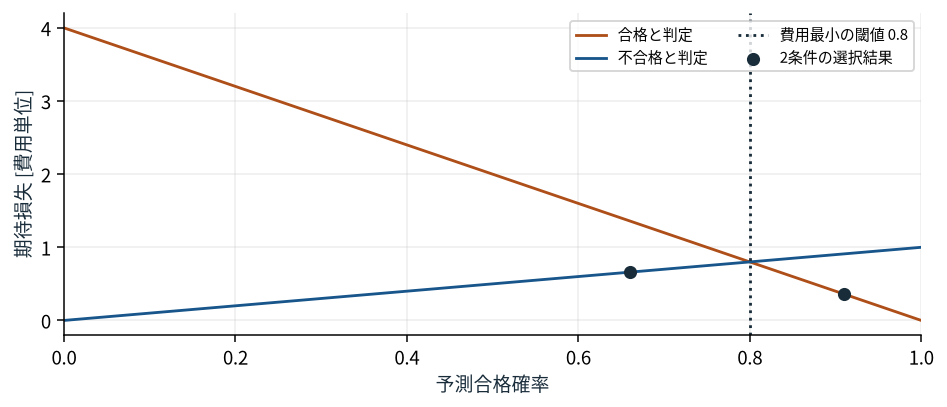

In [2]:
total, initial, confirmation = 20, 6, 4
adaptive_budget = total - initial - confirmation
assert adaptive_budget == 10 and initial + adaptive_budget + confirmation == total

grid = torch.linspace(0, 1, 201)
fig, ax = plt.subplots(figsize=(6.9, 2.9), layout="constrained")
ax.plot(grid, (1 - grid) * cost_false_accept, color=ORANGE, label="合格と判定")
ax.plot(grid, grid * cost_false_reject, color=BLUE, label="不合格と判定")
ax.axvline(threshold, color=INK, linestyle=":", label=f"費用最小の閾値 {threshold:.1f}")
ax.scatter(p, optimal_loss, c=INK, marker="o", zorder=5, label="2条件の選択結果")
ax.set(xlabel="予測合格確率", ylabel="期待損失 [費用単位]", xlim=(0, 1))
ax.legend(ncol=2, loc="upper right", fontsize=8)
save_figure(fig, "ch12_decision_loss")

metrics = {
    "threshold": threshold, "probability": p.tolist(),
    "equal_weight_mean_default_loss": default_loss.mean().item(),
    "equal_weight_mean_optimal_loss": optimal_loss.mean().item(),
    "default_decisions": default.int().tolist(), "optimal_decisions": optimal.int().tolist(),
    "total_budget": total, "initial": initial, "adaptive": adaptive_budget, "confirm": confirmation,
}
(QUALITY / "ch12_metrics.json").write_text(json.dumps(metrics, indent=2) + chr(10), encoding="utf-8")